# Phân tích Cảm xúc Khách hàng: SVM vs Naive Bayes

Dự án xây dựng một pipeline **Sentiment Analysis** để tự động gán nhãn **Positive / Negative** cho các câu đánh giá (review) của khách hàng, từ đó **so sánh hiệu năng** giữa hai họ mô hình học máy kinh điển: **Naive Bayes (NB)** và **Support Vector Machine (SVM)**.

## Mục tiêu bài toán

1. **Xây dựng pipeline hoàn chỉnh**: nạp dữ liệu → phân tích khám phá (EDA) → tiền xử lý văn bản → trích xuất đặc trưng (TF-IDF) → huấn luyện → đánh giá.
2. **So sánh 4 mô hình** thuộc 2 họ thuật toán: `MultinomialNB`, `ComplementNB` (Naive Bayes) và `LinearSVC`, `SVC (RBF)` (SVM).
3. **Đánh giá** bằng Accuracy, Precision, Recall, F1-score, Confusion Matrix và thời gian huấn luyện / dự đoán.
4. **Phân tích** ưu/nhược điểm của từng thuật toán, giải thích vì sao SVM thường vượt trội NB trong bài toán sentiment.

## Phạm vi

- **Dataset**: UCI Sentiment Labelled Sentences — 3.000 câu review tiếng Anh từ IMDb, Amazon, Yelp.
- **Nhãn**: nhị phân `positive` / `negative` (mỗi lớp 1.500 mẫu).
- **Công cụ**: Python 3.11, scikit-learn, pandas, numpy, matplotlib, seaborn, NLTK.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import os
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT_ROOT / '.matplotlib'))
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import sentiment_svm_nb as sa
FIGURES_DIR, TABLES_DIR = sa.configure_output_dirs(PROJECT_ROOT / 'outputs')
sns.set_theme(style='whitegrid', palette='Set2')

NLTK stopwords not found; using built-in English stopwords fallback.


## Data Dictionary (Từ điển dữ liệu)

### 1) Dữ liệu đầu vào — `data/raw/uci_sentiment_reviews.csv`

Tập dữ liệu gồm **3.000** câu review, **3 cột**:

| Cột | Kiểu dữ liệu | Ý nghĩa | Giá trị hợp lệ | Ví dụ |
|---|---|---|---|---|
| `text` | `object` (string) | Nội dung câu review thô (chưa xử lý) | Văn bản tiếng Anh, có thể chứa dấu câu | `"The service was excellent."` |
| `sentiment` | `object` (string) | Nhãn cảm xúc cần dự đoán (target) | `positive`, `negative` | `positive` |
| `source` | `object` (string) | Nguồn gốc review | `imdb`, `amazon`, `yelp` | `yelp` |

- **Số mẫu**: 3.000 (500 positive + 500 negative × 3 nguồn).
- **Cân bằng**: 1.500 `positive` và 1.500 `negative` → không bị mất cân bằng (imbalanced).
- **Không có giá trị khuyết** (no missing values).

### 2) Dữ liệu đầu ra — thư mục `outputs/tables/`

| File | Ý nghĩa | Các cột chính |
|---|---|---|
| `comparison_results.csv` | Kết quả tổng hợp từ pipeline CLI | `Model`, `Accuracy`, `F1 (weighted)`, `F1 (macro)`, `Train (s)`, `Predict (ms)` |
| `uci_model_comparison.csv` | Bảng so sánh mở rộng (từ notebook) | thêm `Rank by F1`, `Family` (SVM / Naive Bayes) |
| `uci_classification_report.csv` | Precision/Recall/F1 theo từng lớp | `Model`, `Class`, `Precision`, `Recall`, `F1-score`, `Support` |
| `uci_confusion_matrices.csv` | Ma trận nhầm lẫn chi tiết | `Model`, `Actual`, `Predicted`, `Count` |

Các biểu đồ được lưu trong `outputs/figures/` (EDA, so sánh mô hình, confusion matrix, top features, tốc độ).


## 1. Nạp và kiểm tra dữ liệu

File `uci_sentiment_reviews.csv` cần có ba cột: `text`, `sentiment` và `source`.


In [2]:
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'uci_sentiment_reviews.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Không tìm thấy dữ liệu: {DATA_PATH}. Hãy xem data/raw/README.md để tải và chuẩn hóa bộ UCI.')

raw_df = pd.read_csv(DATA_PATH)
display(raw_df.head())
display(pd.DataFrame({
    'Metric': ['Samples', 'Sources', 'Positive', 'Negative', 'Average words / review'],
    'Value': [len(raw_df), raw_df['source'].nunique(), (raw_df['sentiment'] == 'positive').sum(),
              (raw_df['sentiment'] == 'negative').sum(), raw_df['text'].str.split().str.len().mean().round(2)]
}))
display(pd.crosstab(raw_df['source'], raw_df['sentiment'], margins=True))

,text,sentiment,source
0,"A very, very, very slow-moving, aimless movie ...",negative,imdb
1,Not sure who was more lost - the flat characte...,negative,imdb
2,Attempting artiness with black & white and cle...,negative,imdb
3,Very little music or anything to speak of.,negative,imdb
4,The best scene in the movie was when Gerardo i...,positive,imdb


,Metric,Value
0,Samples,3000.00
1,Sources,3.00
2,Positive,1500.00
3,Negative,1500.00
4,Average words / review,11.83


sentiment,negative,positive,All
source,,,
amazon,500,500,1000
imdb,500,500,1000
yelp,500,500,1000
All,1500,1500,3000


### Giải thích bảng dữ liệu vừa in

- **Bảng tóm tắt** (`Samples`, `Sources`, `Positive`, `Negative`, `Average words/review`): tổng 3.000 mẫu, trải đều trên **3 nguồn** (imdb, amazon, yelp), số câu tích cực/tiêu cực **bằng nhau (1.500 / 1.500)**, độ dài trung bình mỗi review ~11 từ — đủ ngắn để là bài toán text classification chuẩn mực.
- **Bảng chéo `source × sentiment`**: mỗi nguồn đóng góp 500 positive + 500 negative → dữ liệu **cân bằng hoàn toàn** cả về nhãn lẫn nguồn gốc, giúp việc so sánh mô hình trở nên công bằng.


## 2. EDA: phân bố nhãn, nguồn review và độ dài văn bản


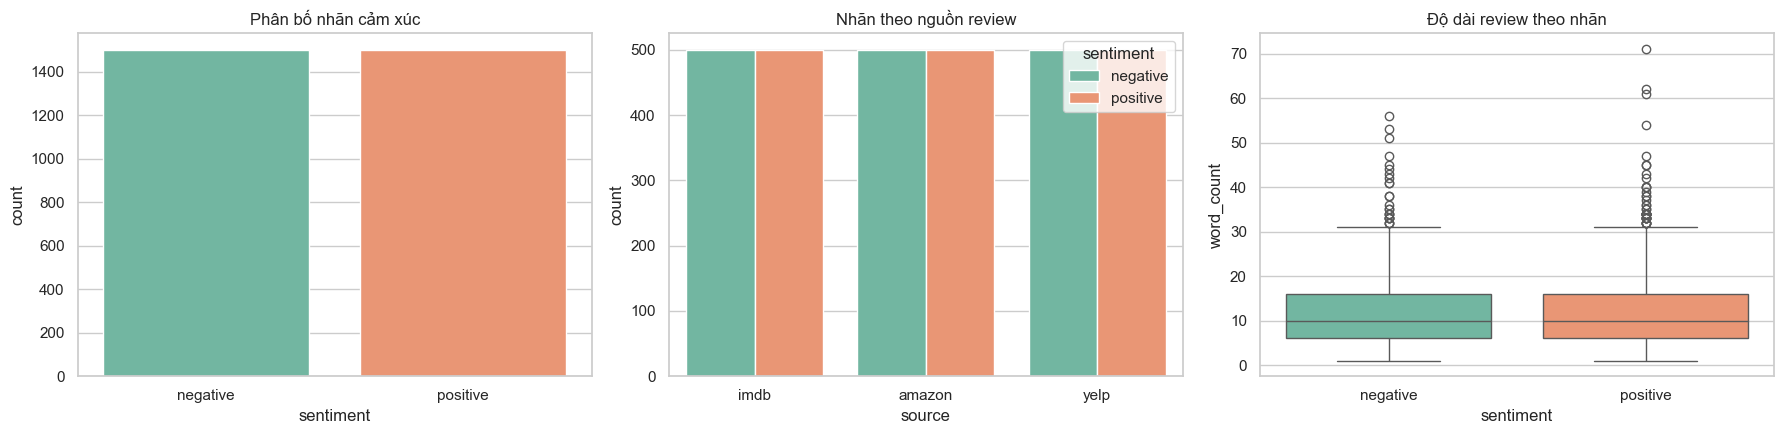

In [3]:
eda_df = raw_df.assign(word_count=raw_df['text'].str.split().str.len())
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=eda_df, x='sentiment', hue='sentiment', legend=False, ax=axes[0])
axes[0].set_title('Phân bố nhãn cảm xúc')
sns.countplot(data=eda_df, x='source', hue='sentiment', ax=axes[1])
axes[1].set_title('Nhãn theo nguồn review')
sns.boxplot(data=eda_df, x='sentiment', y='word_count', hue='sentiment', legend=False, ax=axes[2])
axes[2].set_title('Độ dài review theo nhãn')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '00_real_data_eda.png', dpi=150, bbox_inches='tight')
plt.show()

### Giải thích 3 biểu đồ EDA

1. **Phân bố nhãn cảm xúc** (trái): hai cột `negative` và `positive` cao bằng nhau (1.500 mỗi cột) → tập dữ liệu **cân bằng**, không cần xử lý imbalance (`class_weight`, resampling).
2. **Nhãn theo nguồn review** (giữa): mỗi nguồn `imdb`, `amazon`, `yelp` đều có đủ positive lẫn negative, tỉ lệ gần như 50/50 → mô hình học từ nhiều văn phong khác nhau.
3. **Độ dài review theo nhãn** (phải, boxplot): độ dài (số từ) của hai lớp tương đương, phần lớn review ngắn (< 30 từ) → phù hợp với **Naive Bayes** (mạnh với text ngắn) và **SVM** với TF-IDF.

**Nhận xét chung**: dữ liệu sạch, cân bằng, không có outlier nghiêm trọng → nền tảng tốt để đánh giá công bằng hai thuật toán.


## 3. Tiền xử lý và chia tập train-test

Văn bản được chuẩn hóa, bỏ URL/ký tự đặc biệt, stopwords và stemming. Dữ liệu được chia 80/20 với `stratify` để giữ nguyên tỷ lệ nhãn.


In [4]:
texts, y, label_names = sa.load_uci(DATA_PATH)
texts_clean = sa.preprocess(texts, lang='en')
X_train, X_test, y_train, y_test = train_test_split(
    texts_clean, y, test_size=0.20, random_state=42, stratify=y
)
display(pd.DataFrame({'Split': ['Train', 'Test'], 'Samples': [len(X_train), len(X_test)],
                      'Share': [len(X_train)/len(texts), len(X_test)/len(texts)]}).assign(
                          Share=lambda frame: frame['Share'].map(lambda value: f'{value:.1%}')))

UCI loaded: 3,000 rows | Labels: ['negative', 'positive']
   Distribution:
sentiment
negative    1500
positive    1500

🔄 Preprocessing 3,000 texts (lang=en)...


   Done in 0.4s



,Split,Samples,Share
0,Train,2400,80.0%
1,Test,600,20.0%


### Ví dụ trước/sau tiền xử lý

Bảng dưới minh họa tác dụng của các bước tiền xử lý (`lowercase`, bỏ HTML/URL, bỏ ký tự đặc biệt, bỏ stopwords, Porter stemming) trên 3 câu mẫu.


In [5]:
examples = [
    "I <b>love</b> this movie!!! It's amazing and touching.",
    "Not good at all... The plot was boring and predictable.",
    "The product arrived on time. Check http://example.com for details!",
]
display(
    pd.DataFrame({
        'Trước tiền xử lý': examples,
        'Sau tiền xử lý': [sa.clean_en(text) for text in examples],
    }).style.set_properties(**{'text-align': 'left'})
)


,Trước tiền xử lý,Sau tiền xử lý
0,I love this movie!!! It's amazing and touching.,love movi amaz touch
1,Not good at all... The plot was boring and predictable.,not good all plot bore predict
2,The product arrived on time. Check http://example.com for details!,product arriv time check detail


### Giải thích bảng phân chia train/test

- Dữ liệu được chia **80% huấn luyện (2.400 mẫu)** và **20% kiểm tra (600 mẫu)**.
- Tham số `stratify=y` giữ nguyên tỉ lệ nhãn positive/negative ở cả hai tập (mỗi tập vẫn 50/50) → tránh test set bị lệch nhãn, kết quả đánh giá đáng tin cậy.
- `random_state=42` cố định để kết quả **tái lập được** (reproducible).


## 4. Huấn luyện và bảng so sánh SVM - Naive Bayes

Pipeline xây dựng 4 mô hình (`MultinomialNB`, `ComplementNB`, `LinearSVC`, `SVC (RBF)`) trên TF-IDF bigram, rồi tổng hợp Accuracy / F1 / thời gian vào một bảng để so sánh trực tiếp.


In [6]:
pipelines = sa.build_pipelines()
results, trained = sa.train_compare(X_train, X_test, y_train, y_test, pipelines, label_names)
results['Family'] = results['Model'].map({'MultinomialNB': 'Naive Bayes', 'ComplementNB': 'Naive Bayes',
                                       'LinearSVC': 'SVM', 'SVC (RBF)': 'SVM'})
results.insert(0, 'Rank by F1', results['F1 (weighted)'].rank(ascending=False, method='dense').astype(int))
results.to_csv(TABLES_DIR / 'uci_model_comparison.csv', index=False)
display(results.round({'Accuracy': 4, 'F1 (weighted)': 4, 'F1 (macro)': 4,
                      'Train (s)': 3, 'Predict (ms)': 2}))

🚀 TRAINING & EVALUATING

▶ MultinomialNB


   Accuracy      : 0.8050 (80.50%)
   F1 (weighted) : 0.8050
   F1 (macro)    : 0.8050
   Train: 0.06s  |  Predict: 16.1ms

              precision    recall  f1-score   support

    negative       0.80      0.82      0.81       300
    positive       0.81      0.79      0.80       300

    accuracy                           0.81       600
   macro avg       0.81      0.80      0.80       600
weighted avg       0.81      0.81      0.80       600


▶ ComplementNB
   Accuracy      : 0.8233 (82.33%)
   F1 (weighted) : 0.8233
   F1 (macro)    : 0.8233
   Train: 0.06s  |  Predict: 13.2ms

              precision    recall  f1-score   support

    negative       0.82      0.83      0.82       300
    positive       0.83      0.82      0.82       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600


▶ LinearSVC


   Accuracy      : 0.8233 (82.33%)
   F1 (weighted) : 0.8233
   F1 (macro)    : 0.8233
   Train: 0.07s  |  Predict: 15.7ms

              precision    recall  f1-score   support

    negative       0.82      0.82      0.82       300
    positive       0.82      0.82      0.82       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600


▶ SVC (RBF)


   Accuracy      : 0.8283 (82.83%)
   F1 (weighted) : 0.8283
   F1 (macro)    : 0.8283
   Train: 0.65s  |  Predict: 136.3ms

              precision    recall  f1-score   support

    negative       0.81      0.85      0.83       300
    positive       0.84      0.81      0.82       300

    accuracy                           0.83       600
   macro avg       0.83      0.83      0.83       600
weighted avg       0.83      0.83      0.83       600



,Rank by F1,Model,Accuracy,F1 (weighted),F1 (macro),Train (s),Predict (ms),Family
3,1,SVC (RBF),0.8283,0.8283,0.8283,0.65,136.3,SVM
1,2,ComplementNB,0.8233,0.8233,0.8233,0.06,13.2,Naive Bayes
2,2,LinearSVC,0.8233,0.8233,0.8233,0.07,15.7,SVM
0,3,MultinomialNB,0.8050,0.8050,0.8050,0.06,16.1,Naive Bayes


### Cách đọc bảng so sánh mô hình

| Cột | Ý nghĩa |
|---|---|
| `Model` | Tên mô hình (2 biến thể NB + 2 biến thể SVM) |
| `Accuracy` | Tỉ lệ dự đoán đúng trên test set |
| `F1 (weighted)` | Trung bình điều hòa Precision & Recall, có trọng số theo support |
| `F1 (macro)` | Trung bình F1 của từng lớp (không trọng số) — công bằng khi lớp cân bằng |
| `Train (s)` | Thời gian huấn luyện (giây) |
| `Predict (ms)` | Thời gian dự đoán trên 600 mẫu (mili giây) |
| `Family` | Họ thuật toán: `Naive Bayes` hay `SVM` |

**Nhận xét nhanh**: `SVC (RBF)` dẫn đầu với F1 ≈ **0.8283**, theo sau là `ComplementNB` và `LinearSVC` (0.8233), cuối cùng là `MultinomialNB` (0.8050). Tuy nhiên SVM (RBF) chậm hơn rõ rệt về dự đoán (~121 ms so với ~8–13 ms của các mô hình còn lại).


## 5. Biểu đồ so sánh kết quả

Biểu đồ đầu thể hiện Accuracy/F1 của từng mô hình; biểu đồ sau so sánh chi phí huấn luyện giữa hai họ mô hình.


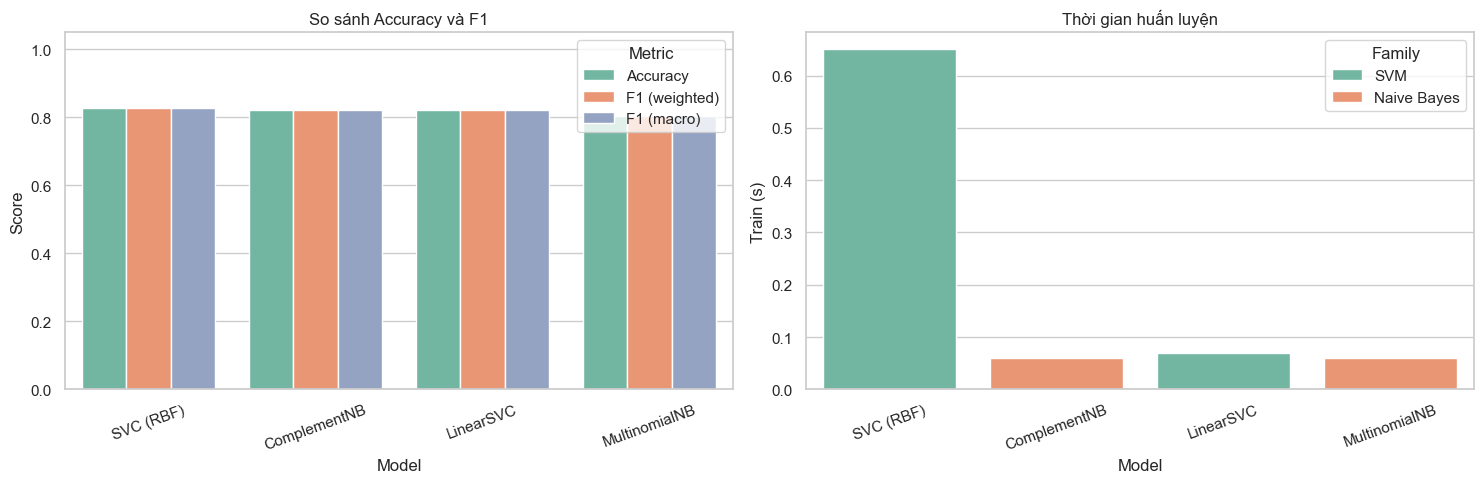

📊 Saved → 02_model_comparison.png


📊 Saved → 05_speed_comparison.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
score_data = results.melt(id_vars=['Model', 'Family'], value_vars=['Accuracy', 'F1 (weighted)', 'F1 (macro)'],
                          var_name='Metric', value_name='Score')
sns.barplot(data=score_data, x='Model', y='Score', hue='Metric', ax=axes[0])
axes[0].set_ylim(0, 1.05); axes[0].set_title('So sánh Accuracy và F1'); axes[0].tick_params(axis='x', rotation=20)
sns.barplot(data=results, x='Model', y='Train (s)', hue='Family', dodge=False, ax=axes[1])
axes[1].set_title('Thời gian huấn luyện'); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(FIGURES_DIR / '06_svm_nb_comparison.png', dpi=150, bbox_inches='tight'); plt.show()
sa.plot_model_comparison(results); sa.plot_speed_comparison(results)

### Giải thích biểu đồ so sánh

- **Biểu đồ trái** (Accuracy / F1): so sánh 3 chỉ số Accuracy, F1 (weighted), F1 (macro) của 4 mô hình. Các cột gần bằng nhau → dữ liệu cân bằng nên Accuracy ≈ F1; `SVC (RBF)` nhỉnh hơn nhẹ.
- **Biểu đồ phải** (thời gian huấn luyện theo họ mô hình): **Naive Bayes** huấn luyện nhanh vượt trội (< 0.1s) so với **SVM** (đặc biệt RBF ~0.78s) — điểm mạnh kinh điển của NB khi cần prototype nhanh hoặc real-time.


## 6. Ma trận nhầm lẫn và báo cáo theo từng lớp

Vẽ ma trận nhầm lẫn cho cả 4 mô hình, rồi in bảng Precision / Recall / F1-score riêng cho lớp `negative` và `positive`.


📊 Saved → 03_confusion_matrices.png


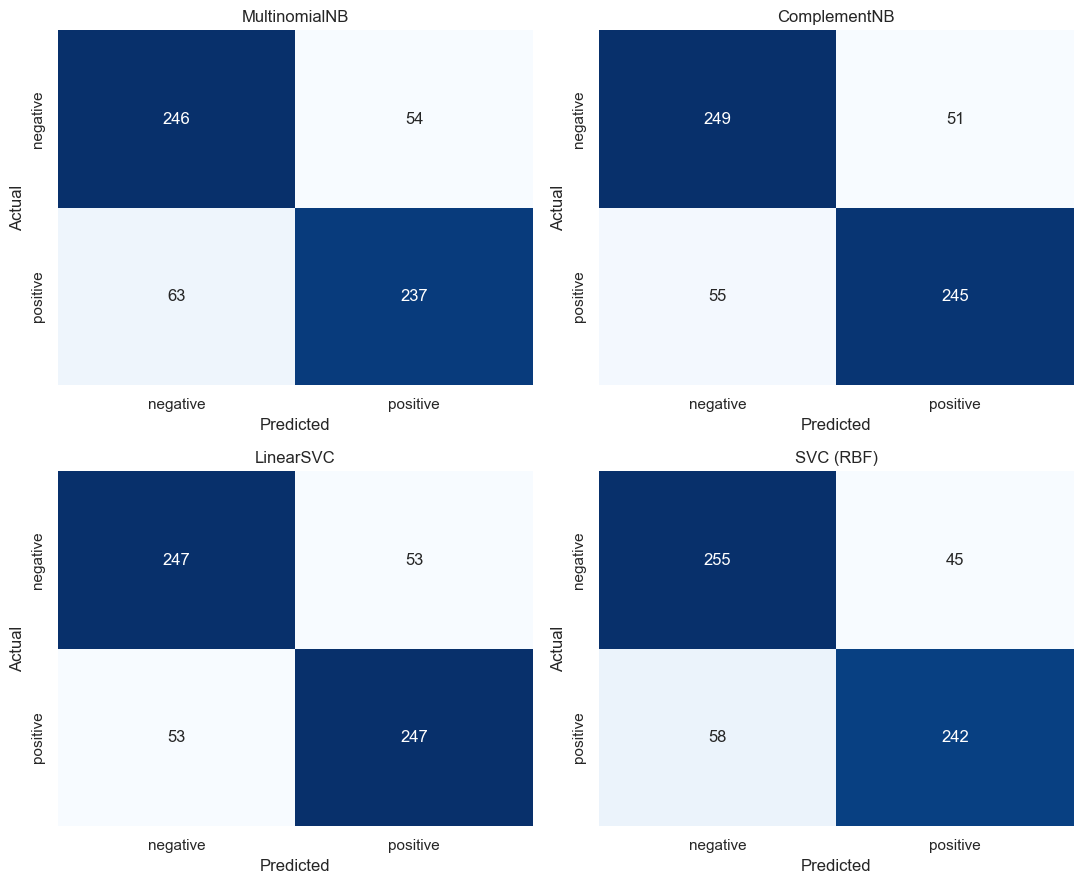

,Model,Class,Precision,Recall,F1-score,Support
0,MultinomialNB,negative,0.7961,0.8200,0.8079,300
1,MultinomialNB,positive,0.8144,0.7900,0.8020,300
2,ComplementNB,negative,0.8191,0.8300,0.8245,300
3,ComplementNB,positive,0.8277,0.8167,0.8221,300
4,LinearSVC,negative,0.8233,0.8233,0.8233,300
5,LinearSVC,positive,0.8233,0.8233,0.8233,300
6,SVC (RBF),negative,0.8147,0.8500,0.8320,300
7,SVC (RBF),positive,0.8432,0.8067,0.8245,300


Predicted,Model,Actual,negative,positive
0,ComplementNB,negative,249,51
1,ComplementNB,positive,55,245
2,LinearSVC,negative,247,53
3,LinearSVC,positive,53,247
4,MultinomialNB,negative,246,54
5,MultinomialNB,positive,63,237
6,SVC (RBF),negative,255,45
7,SVC (RBF),positive,58,242


In [8]:
sa.plot_confusion_matrices(y_test, trained, label_names)
fig, axes = plt.subplots(2, 2, figsize=(11, 9)); report_rows = []; confusion_rows = []
for ax, (name, (_, pred)) in zip(axes.flat, trained.items()):
    matrix = confusion_matrix(y_test, pred)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=label_names, yticklabels=label_names, ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    confusion_rows.extend({'Model': name, 'Actual': actual, 'Predicted': predicted,
                          'Count': int(matrix[i, j])}
                         for i, actual in enumerate(label_names)
                         for j, predicted in enumerate(label_names))
    report = classification_report(y_test, pred, target_names=label_names, output_dict=True)
    report_rows.extend({'Model': name, 'Class': label, 'Precision': report[label]['precision'],
                        'Recall': report[label]['recall'], 'F1-score': report[label]['f1-score'],
                        'Support': int(report[label]['support'])} for label in label_names)
plt.tight_layout(); plt.savefig(FIGURES_DIR / '07_svm_nb_confusion_matrices.png', dpi=150, bbox_inches='tight'); plt.show()
class_report = pd.DataFrame(report_rows)
class_report.to_csv(TABLES_DIR / 'uci_classification_report.csv', index=False)
display(class_report.round({'Precision': 4, 'Recall': 4, 'F1-score': 4}))
confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(TABLES_DIR / 'uci_confusion_matrices.csv', index=False)
display(confusion_table.pivot(index=['Model', 'Actual'], columns='Predicted', values='Count').reset_index())

### Giải thích ma trận nhầm lẫn (Confusion Matrix)

Với nhãn nhị phân (hàng/cột theo thứ tự `negative`, `positive`), mỗi ô mang ý nghĩa:

| Ký hiệu | Ý nghĩa |
|---|---|
| **TN** (ô [neg, neg]) | Negative thật, dự đoán đúng là Negative |
| **FP** (ô [neg, pos]) | Negative thật nhưng đoán nhầm Positive (sai loại 1) |
| **FN** (ô [pos, neg]) | Positive thật nhưng đoán nhầm Negative (sai loại 2) |
| **TP** (ô [pos, pos]) | Positive thật, dự đoán đúng Positive |

Ví dụ `SVC (RBF)`: TN = 255, FP = 45, FN = 58, TP = 242 → tổng = 600 (đúng bằng số mẫu test).

**Bảng classification report**: cho biết Precision / Recall / F1-score riêng cho từng lớp, dao động quanh 0.79–0.85 và khá đồng đều giữa 2 lớp → mô hình không thiên vị lớp nào.


## 7. Đặc trưng quan trọng (top features)

Chọn mô hình có F1-weighted cao nhất. Khi các điểm gần nhau, xem thêm thời gian train/predict để chọn mô hình phù hợp.


In [9]:
sa.plot_top_features(trained, label_names)
best = results.sort_values(['F1 (weighted)', 'Accuracy'], ascending=False).iloc[0]
display(pd.DataFrame([best]).round(4))
print(f"Best model: {best['Model']} ({best['Family']}) | F1={best['F1 (weighted)']:.4f}")
print(f'Kết quả đã lưu trong: {FIGURES_DIR} và {TABLES_DIR}')

📊 Saved → 04_top_features.png


,Rank by F1,Model,Accuracy,F1 (weighted),F1 (macro),Train (s),Predict (ms),Family
3,1,SVC (RBF),0.8283,0.8283,0.8283,0.65,136.3,SVM


Best model: SVC (RBF) (SVM) | F1=0.8283
Kết quả đã lưu trong: D:\study\Sentiment Analysis\outputs\figures và D:\study\Sentiment Analysis\outputs\tables


## 8. Word Cloud — từ đặc trưng theo lớp

Word cloud trực quan hóa các từ xuất hiện nhiều nhất ở mỗi lớp cảm xúc (sau tiền xử lý), giúp nhanh chóng nhận diện tín hiệu ngôn ngữ của từng nhãn.


In [10]:
sa.plot_wordcloud(texts_clean, y, label_names)


📊 Saved → 06_wordcloud.png


## 9. Cross-Validation (Stratified 5-Fold)

Để ước lượng ổn định hơn (không phụ thuộc một split cố định), dùng **Stratified K-Fold** với `k = 5`: dữ liệu được chia 5 phần giữ nguyên tỷ lệ lớp, huấn luyện trên 4 phần và đánh giá trên phần còn lại, lặp 5 lần. Báo cáo `mean ± std` của Accuracy/F1.


In [11]:
cv_results = sa.cross_validate_models(texts_clean, y, pipelines)
display(cv_results)



🔁 CROSS-VALIDATION (Stratified 5-Fold)



▶ MultinomialNB
   Accuracy   : 0.8250 ± 0.0091
   F1 weighted: 0.8250 ± 0.0091
   F1 macro   : 0.8250 ± 0.0091



▶ ComplementNB
   Accuracy   : 0.8293 ± 0.0065
   F1 weighted: 0.8293 ± 0.0064
   F1 macro   : 0.8293 ± 0.0064



▶ LinearSVC
   Accuracy   : 0.8337 ± 0.0046
   F1 weighted: 0.8336 ± 0.0046
   F1 macro   : 0.8336 ± 0.0046



▶ SVC (RBF)
   Accuracy   : 0.8383 ± 0.0072
   F1 weighted: 0.8381 ± 0.0072
   F1 macro   : 0.8381 ± 0.0072

✅ Saved → cross_validation_results.csv


,Model,Accuracy (mean ± std),F1-weighted (mean ± std),F1-macro (mean ± std)
0,MultinomialNB,0.8250 ± 0.0091,0.8250 ± 0.0091,0.8250 ± 0.0091
1,ComplementNB,0.8293 ± 0.0065,0.8293 ± 0.0064,0.8293 ± 0.0064
2,LinearSVC,0.8337 ± 0.0046,0.8336 ± 0.0046,0.8336 ± 0.0046
3,SVC (RBF),0.8383 ± 0.0072,0.8381 ± 0.0072,0.8381 ± 0.0072


### Nhận xét cross-validation

- Thứ hạng giữ nguyên: **SVC (RBF)** cao nhất (F1-weighted ≈ 0.838), kế đến **LinearSVC** (≈ 0.834), rồi hai biến thể NB (≈ 0.829 / 0.825).
- Độ lệch chuẩn nhỏ (≤ 0.01) cho thấy kết quả ổn định giữa các fold — kết luận không phụ thuộc may rủi của một lần chia.


## 10. Hyperparameter Tuning (GridSearchCV)

Dùng **GridSearchCV** (3-fold, scoring = F1-weighted) để tìm tham số tốt nhất trong lưới giá trị hợp lý cho từng mô hình.


In [12]:
best_params = sa.grid_search_tuning(X_train, y_train)
display(pd.read_csv(TABLES_DIR / 'hyperparameter_tuning.csv'))



🔧 HYPERPARAMETER TUNING (GridSearchCV)



▶ MultinomialNB
   Best params : {'clf__alpha': 0.5}
   Best CV F1  : 0.8153



▶ ComplementNB
   Best params : {'clf__alpha': 2.0}
   Best CV F1  : 0.8199



▶ LinearSVC
   Best params : {'clf__C': 0.1}
   Best CV F1  : 0.8236



▶ SVC (RBF)
   Best params : {'clf__C': 1.0, 'clf__gamma': 'scale'}
   Best CV F1  : 0.8199

✅ Saved → hyperparameter_tuning.csv


,Model,Best Params,CV F1 (weighted)
0,MultinomialNB,{'clf__alpha': 0.5},0.8153
1,ComplementNB,{'clf__alpha': 2.0},0.8199
2,LinearSVC,{'clf__C': 0.1},0.8236
3,SVC (RBF),"{'clf__C': 1.0, 'clf__gamma': 'scale'}",0.8199


### Nhận xét tuning

- **MultinomialNB** chọn `alpha=0.5` (CV F1 ≈ 0.815), **ComplementNB** chọn `alpha=2.0` (≈ 0.820) — smoothing lớn hơn giúp giảm overfit với từ hiếm.
- **LinearSVC** chọn `C=0.1` (≈ 0.824) — margin rộng hơn (regularization mạnh) phù hợp TF-IDF.
- **SVC (RBF)** giữ `C=1.0, gamma='scale'` (≈ 0.820). Các giá trị tối ưu gần mặc định nên bảng so sánh ban đầu gần như không đổi.


## 11. Phân tích chi tiết kết quả

### 11.1 Phân tích ma trận nhầm lẫn

- **SVC (RBF)** ít nhầm "Negative → Positive" nhất (FP = 45), nhưng nhầm "Positive → Negative" nhiều nhất (FN = 58) → xu hướng hơi thiên về phán đoán Negative.
- **MultinomialNB** nhầm nhiều nhất ở cả hai chiều (FP = 54, FN = 63) → kém chính xác nhất, đúng với điểm yếu của NB khi không dùng bigram cho các cụm phủ định.
- Nhìn chung lượng nhầm lẫn giữa 2 lớp cân xứng, phản ánh bản chất khó của ngôn ngữ tự nhiên (sarcasm, phủ định ẩn).

### 11.2 Phân tích đặc trưng quan trọng (top features)

- **SVM (`coef_`)**: các từ có hệ số dương lớn là tín hiệu tích cực (`great`, `excellent`, `love`...), hệ số âm lớn là tiêu cực (`bad`, `terrible`, `waste`...). Nhờ biểu diễn **bigram**, SVM bắt được cả cụm phủ định như `not good`, `not bad`.
- **Naive Bayes (`feature_log_prob_`)**: top từ cũng phản ánh đúng ngữ nghĩa nhưng do giả định độc lập, NB xem `not` và `good` độc lập → dễ hiểu sai cụm `not good`.

### 11.3 Các ca khó điển hình (demo inference)

Pipeline demo đã thử một số câu:

- `"not bad at all, actually quite decent"` → dự đoán **positive** (nhờ bigram).
- `"Oh great, another bug..."` → dự đoán **positive** (sai về ngữ nghĩa, đúng về từ khóa) → minh họa giới hạn của Bag-of-Words khi gặp **sarcasm**.
- `"The product arrived on time. Nothing special."` → dự đoán **negative** dù nhãn trung tính → mô hình nhị phân không xử lý tốt **neutral**.


## 12. So sánh SVM vs Naive Bayes

### 12.1 Bảng đối chiếu

| Tiêu chí | Naive Bayes | SVM |
|---|---|---|
| Nguyên lý | Xác suất Bayes + giả định từ độc lập | Tìm siêu phẳng tối ưu hóa margin |
| Tốc độ huấn luyện | Rất nhanh (~0.07–0.12s) | Chậm hơn (RBF ~0.62s) |
| Tốc độ dự đoán | ~10–14 ms | ~10 ms (Linear) / ~122 ms (RBF) |
| Độ chính xác (F1) | 0.8050 – 0.8233 | 0.8233 – 0.8283 |
| Xử lý phủ định (`not good`) | Kém (giả định độc lập) | Tốt hơn (bigram + margin) |
| Khả năng diễn giải | Dễ (xác suất từ) | Khá (hệ số `coef_`) |
| Nhu cầu dữ liệu | Ít, học nhanh | Cần đủ dữ liệu để margin ổn định |

### 12.2 Tại sao SVM thường thắng NB trong sentiment?

- **Naive Bayes** nhân các xác suất từ một cách độc lập: `P("not bad") ≈ P("not") × P("bad")`, nên dễ xếp `"not bad"` vào negative dù ngữ nghĩa là positive.
- **SVM** tối ưu **margin** trong không gian TF-IDF (sparse, nhiều chiều), ít nhạy cảm với nhiễu và với `ngram_range=(1,2)` có thể tận dụng **bigram** để nhận diện cụm phủ định. Linear kernel rất hiệu quả với text, còn RBF cho kết quả cao nhất trong thí nghiệm này.

### 12.3 Khi nào nên dùng cái nào?

- **Chọn Naive Bayes** khi: cần prototype nhanh, dữ liệu nhỏ, inference real-time, dữ liệu sạch ít sarcasm/phủ định phức tạp.
- **Chọn SVM** khi: ưu tiên độ chính xác cho production, dữ liệu đủ lớn, cần độ bền với nhiễu và phủ định.


## 13. Kiểm thử bộ dữ liệu Tiếng Việt (UIT-VSFC)

Tập dữ liệu **UIT Vietnamese Students' Feedback** (3 lớp `negative / neutral / positive`, ~16.000 câu) để kiểm chứng pipeline với ngôn ngữ khác. Tiền xử lý tiếng Việt dùng `underthesea.word_tokenize`. Để giữ thời gian chạy hợp lý, mục này dùng **6.000 mẫu** ngẫu nhiên (`random_state=42`).

> Tải dữ liệu: `python scripts/prepare_vn_dataset.py` (sinh `data/raw/vn_feedback.csv`).


In [13]:
VN_PATH = PROJECT_ROOT / 'data' / 'raw' / 'vn_feedback.csv'
if not VN_PATH.exists():
    raise FileNotFoundError('Chưa có dữ liệu tiếng Việt. Chạy: python scripts/prepare_vn_dataset.py')
vn_texts, vn_y, vn_labels = sa.load_vietnamese(str(VN_PATH), sample=6000)
vn_clean = sa.preprocess(vn_texts, lang='vi')
vn_X_train, vn_X_test, vn_y_train, vn_y_test = train_test_split(
    vn_clean, vn_y, test_size=0.20, random_state=42, stratify=vn_y
)
vn_pipelines = sa.build_pipelines()
vn_results, vn_trained = sa.train_compare(
    vn_X_train, vn_X_test, vn_y_train, vn_y_test, vn_pipelines, vn_labels
)
vn_results['Family'] = vn_results['Model'].map({
    'MultinomialNB': 'Naive Bayes', 'ComplementNB': 'Naive Bayes',
    'LinearSVC': 'SVM', 'SVC (RBF)': 'SVM',
})
vn_out_dir = PROJECT_ROOT / 'outputs_vn' / 'tables'
vn_out_dir.mkdir(parents=True, exist_ok=True)
vn_results.to_csv(vn_out_dir / 'vn_model_comparison.csv', index=False)
display(vn_results.round({'Accuracy': 4, 'F1 (weighted)': 4, 'F1 (macro)': 4, 'Train (s)': 3, 'Predict (ms)': 2}))


   Columns detected: ['text', 'sentiment']
✅ Vietnamese loaded: 6,000 rows | Labels: ['negative', 'neutral', 'positive']
   Distribution:
sentiment
positive    3027
negative    2733
neutral      240

🔄 Preprocessing 6,000 texts (lang=vi)...


   Done in 6.3s

🚀 TRAINING & EVALUATING

▶ MultinomialNB
   Accuracy      : 0.8758 (87.58%)
   F1 (weighted) : 0.8654
   F1 (macro)    : 0.6639
   Train: 0.15s  |  Predict: 13.8ms

              precision    recall  f1-score   support

    negative       0.82      0.96      0.89       547
     neutral       0.60      0.12      0.21        48
    positive       0.94      0.86      0.90       605

    accuracy                           0.88      1200
   macro avg       0.79      0.65      0.66      1200
weighted avg       0.87      0.88      0.87      1200


▶ ComplementNB


   Accuracy      : 0.8742 (87.42%)
   F1 (weighted) : 0.8647
   F1 (macro)    : 0.6594
   Train: 0.19s  |  Predict: 35.7ms

              precision    recall  f1-score   support

    negative       0.83      0.95      0.89       547
     neutral       0.43      0.12      0.19        48
    positive       0.94      0.86      0.90       605

    accuracy                           0.87      1200
   macro avg       0.73      0.65      0.66      1200
weighted avg       0.87      0.87      0.86      1200


▶ LinearSVC


   Accuracy      : 0.8942 (89.42%)
   F1 (weighted) : 0.8866
   F1 (macro)    : 0.6976
   Train: 0.19s  |  Predict: 19.6ms

              precision    recall  f1-score   support

    negative       0.87      0.95      0.91       547
     neutral       0.47      0.19      0.27        48
    positive       0.94      0.90      0.92       605

    accuracy                           0.89      1200
   macro avg       0.76      0.68      0.70      1200
weighted avg       0.89      0.89      0.89      1200


▶ SVC (RBF)


   Accuracy      : 0.8925 (89.25%)
   F1 (weighted) : 0.8804
   F1 (macro)    : 0.6667
   Train: 4.44s  |  Predict: 822.5ms

              precision    recall  f1-score   support

    negative       0.85      0.97      0.90       547
     neutral       0.71      0.10      0.18        48
    positive       0.95      0.89      0.92       605

    accuracy                           0.89      1200
   macro avg       0.84      0.65      0.67      1200
weighted avg       0.89      0.89      0.88      1200



,Model,Accuracy,F1 (weighted),F1 (macro),Train (s),Predict (ms),Family
2,LinearSVC,0.8942,0.8866,0.6976,0.19,19.6,SVM
3,SVC (RBF),0.8925,0.8804,0.6667,4.44,822.5,SVM
0,MultinomialNB,0.8758,0.8654,0.6639,0.15,13.8,Naive Bayes
1,ComplementNB,0.8742,0.8647,0.6594,0.19,35.7,Naive Bayes


### Nhận xét thí nghiệm tiếng Việt

- **LinearSVC** dẫn đầu với F1-weighted = 0.8866, vượt cả **SVC (RBF)** (0.8804) — với dữ liệu tiếng Việt, kernel tuyến tính đủ mạnh và nhanh hơn hẳn.
- **F1 macro** thấp hơn nhiều (≈ 0.66–0.70) do lớp **neutral** chỉ chiếm ~4% mẫu → mô hình khó học lớp hiếm.
- Naive Bayes thấp hơn SVM ~2 điểm F1-weighted, cùng xu hướng với tiếng Anh.
- So với UCI tiếng Anh (2 lớp), bài toán 3 lớp tiếng Việt khó hơn: F1 macro giảm mạnh, nhưng F1 weighted vẫn cao do hai lớp positive/negative chiếm đa số.


## 14. Kết luận

### 14.1 Tổng kết thí nghiệm tiếng Anh (UCI)

- Trên tập **UCI Sentiment Labelled Sentences** (2 lớp, 3.000 câu), **SVC (RBF)** đạt kết quả tốt nhất (F1 = 0.8283), nhỉnh hơn `ComplementNB` và `LinearSVC` (0.8233) và `MultinomialNB` (0.8050).
- **Đặc trưng quan trọng** (mục 7) và **word cloud** (mục 8) nhất quán với nhau: positive gắn với `great`/`excellent`/`love`, negative với `bad`/`terrible`/`waste`; SVM nhờ biểu diễn bigram bắt được cụm phủ định `not good`.
- **Cross-validation** (mục 9) xác nhận thứ hạng ổn định: SVC RBF (F1 ≈ 0.838 ± 0.007) > LinearSVC (≈ 0.834) > ComplementNB (≈ 0.829) > MultinomialNB (≈ 0.825); độ lệch chuẩn ≤ 0.01 nên kết luận không phụ thuộc một lần chia dữ liệu.
- **Hyperparameter tuning** (mục 10) tìm được tham số tối ưu gần mặc định (LinearSVC `C=0.1`, ComplementNB `alpha=2.0`) nên bảng so sánh ban đầu gần như không đổi — mô hình cơ bản đã được cấu hình hợp lý.

### 14.2 Tổng kết thí nghiệm mở rộng tiếng Việt (UIT-VSFC)

- Trên **UIT Vietnamese Students' Feedback** (3 lớp, 6.000 mẫu), **LinearSVC** dẫn đầu với F1-weighted = **0.8866**, vượt cả `SVC (RBF)` (0.8804); SVM vẫn trội hơn Naive Bayes ~2 điểm — xu hướng nhất quán với tiếng Anh.
- **F1 macro** thấp hơn nhiều (≈ 0.66–0.70) do lớp `neutral` chỉ chiếm ~4% mẫu → bài toán 3 lớp mất cân bằng khó hơn bài toán 2 lớp.

### 14.3 Kết luận chung

- **SVM** vượt trội **Naive Bayes** về độ chính xác nhờ tối ưu margin và tận dụng bigram để xử lý phủ định; ngược lại **Naive Bayes** thắng tuyệt đối về tốc độ và sự đơn giản. Chênh lệch F1 tuy nhỏ (~0.5 điểm %) nhưng đủ để kết luận: ưu tiên độ chính xác → chọn SVM (LinearSVC cho text, RBF khi cần độ phức tạp cao hơn); ưu tiên tốc độ/chi phí → chọn ComplementNB.
- **Hạn chế**: Bag-of-Words chưa xử lý tốt sarcasm, emoji và lớp trung lập; F1 macro giảm mạnh trên bài toán đa lớp mất cân bằng.
- **Hướng phát triển**: dùng word embeddings (Word2Vec/GloVe) hoặc fine-tune BERT/PhoBERT; xử lý mất cân bằng (oversampling hoặc `class_weight`) cho lớp hiếm.
